In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import pickle

In [9]:
import glob
sims = {int(f[-11:-8]): pd.read_parquet(f) for f in sorted(glob.glob("outputs/var_6h/simulaciones/sim_*.parquet"))}
harm_std_pcs = pickle.load(open("outputs/var_6h/harm_std_pcs.pkl", "rb"))
pcs_sel_6h = pd.read_csv("outputs/pca/pcs_msl_sel_6h.csv", index_col=0, parse_dates=True)
print(len(sims), sims[0].shape)

100 (127107, 30)


media (100, 12, 30)
std (100, 12, 30)
acf (100, 21, 30)
corr (100, 435)
guardadas en outputs/var_6h/validacion/


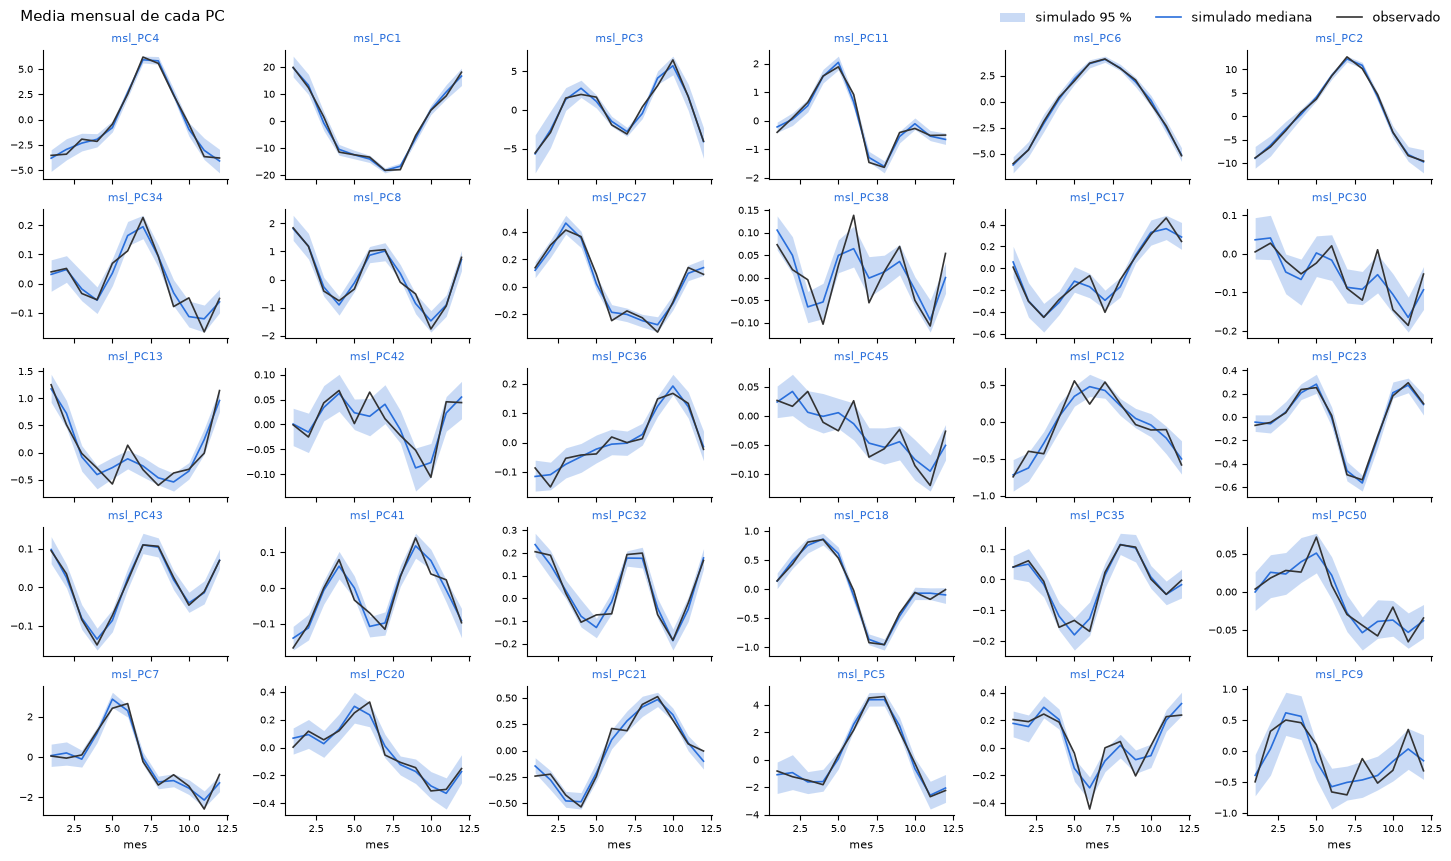

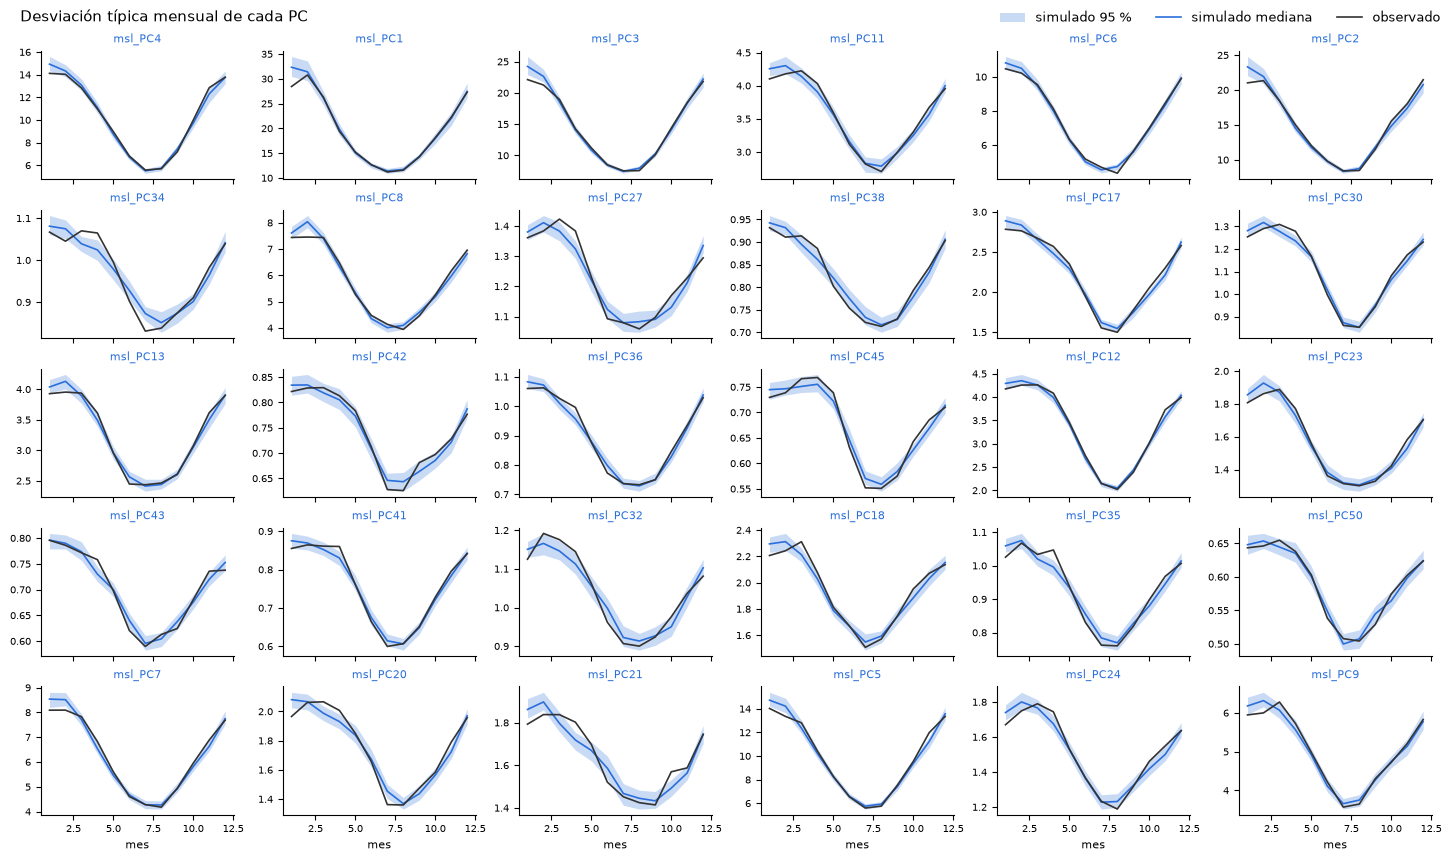

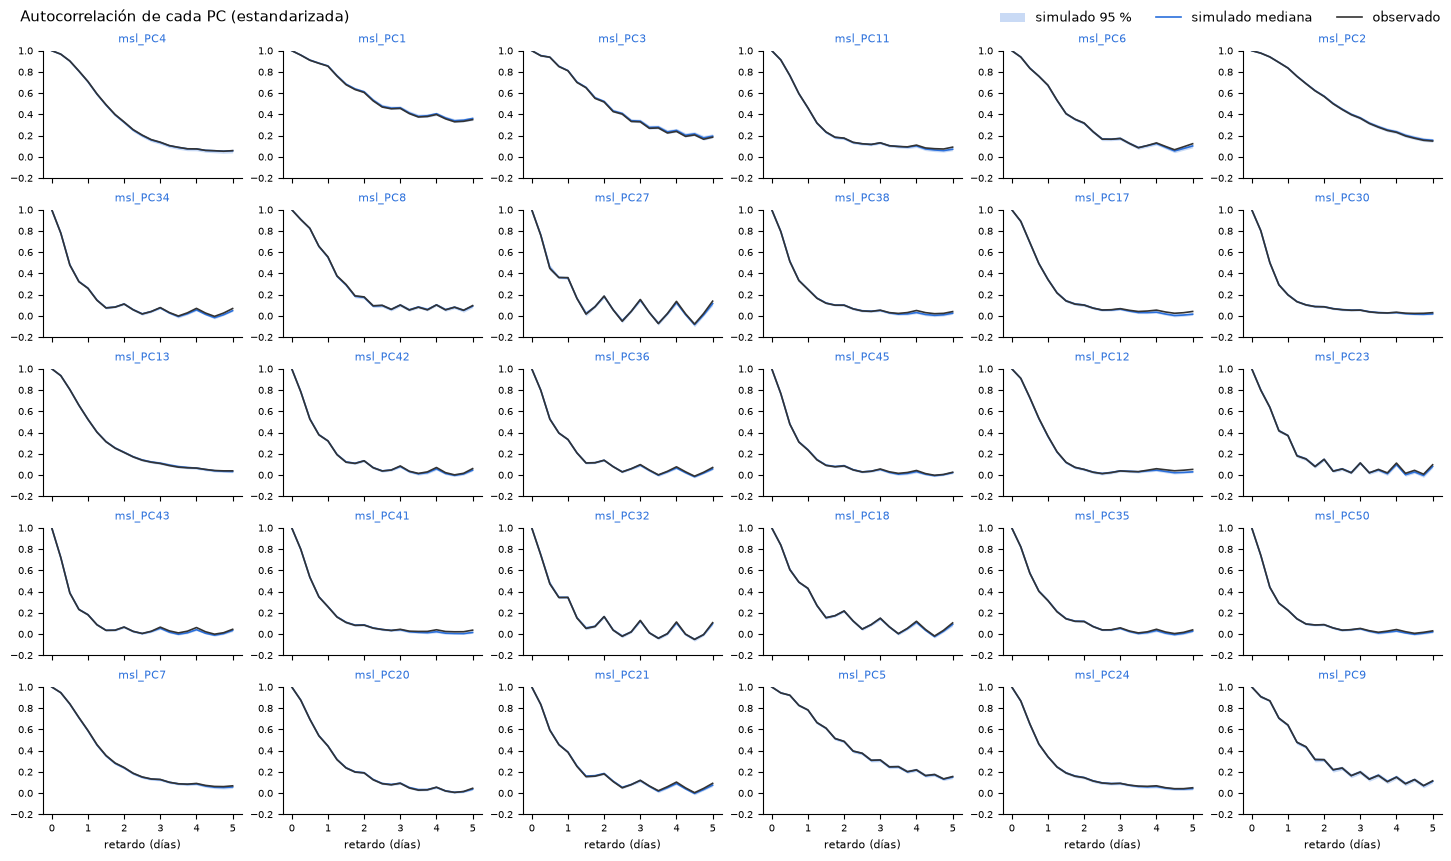

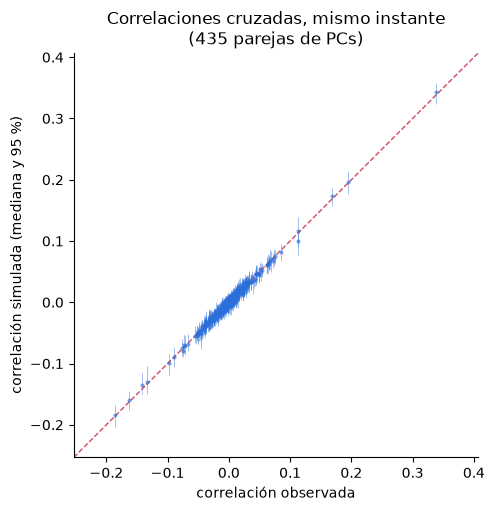

In [3]:
import os
os.makedirs("outputs/var_6h/validacion", exist_ok=True)
cols = list(pcs_sel_6h.columns)
meses = np.arange(1, 13)
lags_acf = np.arange(0, 21)                                    # 0–20 pasos de 6 h = 5 días

#### Estadísticos: observado (x, pc) y simulaciones (sim, x, pc)
def media_mes(df): return df.groupby(df.index.month).mean()[cols].values
def std_mes(df):   return df.groupby(df.index.month).std()[cols].values
def acf(df):
    z = harm_std_pcs.transform(df)[cols].values
    z = (z - np.nanmean(z, 0)) / np.nanstd(z, 0)
    n = len(z)
    return np.array([np.nanmean(z[:n - l] * z[l:], 0) for l in lags_acf])

def corr0(df):                                                 # correlaciones cruzadas en el mismo instante
    c = harm_std_pcs.transform(df)[cols].corr().values
    return c[np.triu_indices(len(cols), 1)]

obs, sim = {}, {}
for nombre, fun in [("media", media_mes), ("std", std_mes), ("acf", acf), ("corr", corr0)]:
    obs[nombre] = fun(pcs_sel_6h)
    sim[nombre] = np.stack([fun(s) for s in sims.values()])
    print(nombre, sim[nombre].shape)

#### Rejilla con banda 2,5–97,5 % de las simulaciones
def rejilla_banda(x, o, s, xlabel, titulo, ylim=None, ncol=6):
    nrow = int(np.ceil(len(cols) / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(2.4 * ncol, 1.7 * nrow), sharex=True, constrained_layout=True)
    lo, mid, hi = np.percentile(s, [2.5, 50, 97.5], axis=0)
    for j, (ax, pc) in enumerate(zip(axs.flat, cols)):
        ax.fill_between(x, lo[:, j], hi[:, j], color="#2a6fdb", alpha=0.25, lw=0)
        ax.plot(x, mid[:, j], color="#2a6fdb", lw=1.2)
        ax.plot(x, o[:, j], color="0.2", lw=1.2)
        ax.set_title(pc, fontsize=8, color="#d1495b" if pc.startswith("grad") else "#2a6fdb")
        ax.tick_params(labelsize=7)
        ax.spines[["top", "right"]].set_visible(False)
        if ylim is not None:
            ax.set_ylim(ylim)
    for ax in axs.flat[len(cols):]:
        ax.axis("off")
    for ax in axs[-1]:
        ax.set_xlabel(xlabel, fontsize=8)
    fig.legend(["simulado 95 %", "simulado mediana", "observado"], loc="upper right", ncol=3, frameon=False, fontsize=9)
    fig.suptitle(titulo, x=0.01, ha="left", fontsize=11)
    return fig

figs = {
    "1_media_mensual": rejilla_banda(meses, obs["media"], sim["media"], "mes", "Media mensual de cada PC"),
    "2_std_mensual":   rejilla_banda(meses, obs["std"], sim["std"], "mes", "Desviación típica mensual de cada PC"),
    "3_autocorrelacion": rejilla_banda(lags_acf * 6 / 24, obs["acf"], sim["acf"], "retardo (días)",
                                       "Autocorrelación de cada PC (estandarizada)", ylim=(-0.2, 1)),
}

#### Correlaciones cruzadas: observada frente a simulada, una por pareja de PCs
lo, mid, hi = np.percentile(sim["corr"], [2.5, 50, 97.5], axis=0)
fig, ax = plt.subplots(figsize=(5, 5), constrained_layout=True)
ax.errorbar(obs["corr"], mid, yerr=[mid - lo, hi - mid], fmt="o", ms=2, color="#2a6fdb", ecolor="#2a6fdb", alpha=0.5, lw=0.6)
lim = [min(obs["corr"].min(), lo.min()) - 0.05, max(obs["corr"].max(), hi.max()) + 0.05]
ax.plot(lim, lim, color="#d1495b", lw=1, ls="--")
ax.set(xlim=lim, ylim=lim, aspect="equal", xlabel="correlación observada", ylabel="correlación simulada (mediana y 95 %)",
       title=f"Correlaciones cruzadas, mismo instante\n({len(obs['corr'])} parejas de PCs)")
ax.spines[["top", "right"]].set_visible(False)
figs["4_correlaciones_cruzadas"] = fig

for nombre, f in figs.items():
    f.savefig(f"outputs/var_6h/validacion/{nombre}.png", dpi=150)
print("guardadas en outputs/var_6h/validacion/")

guardadas


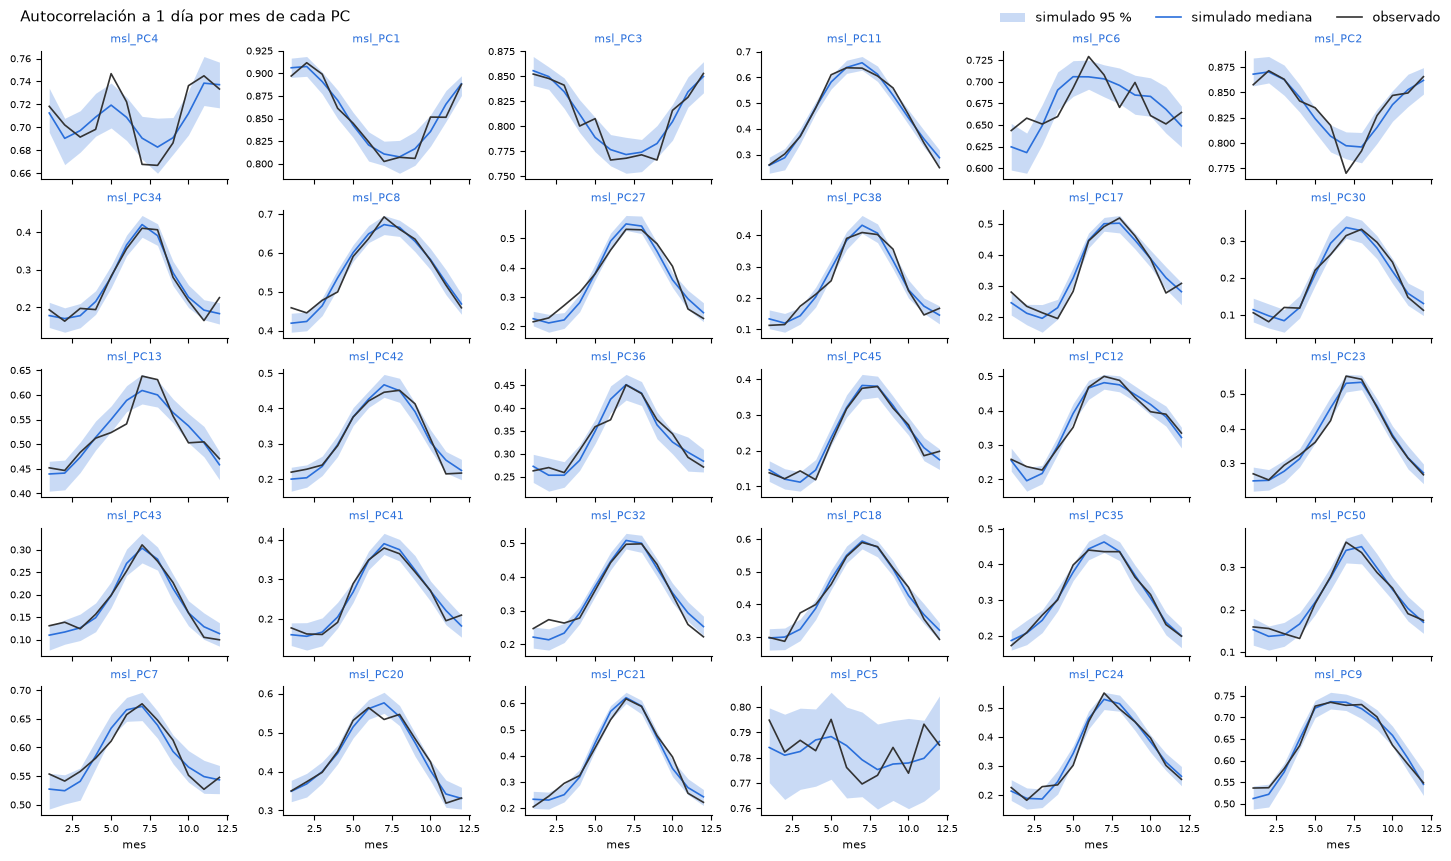

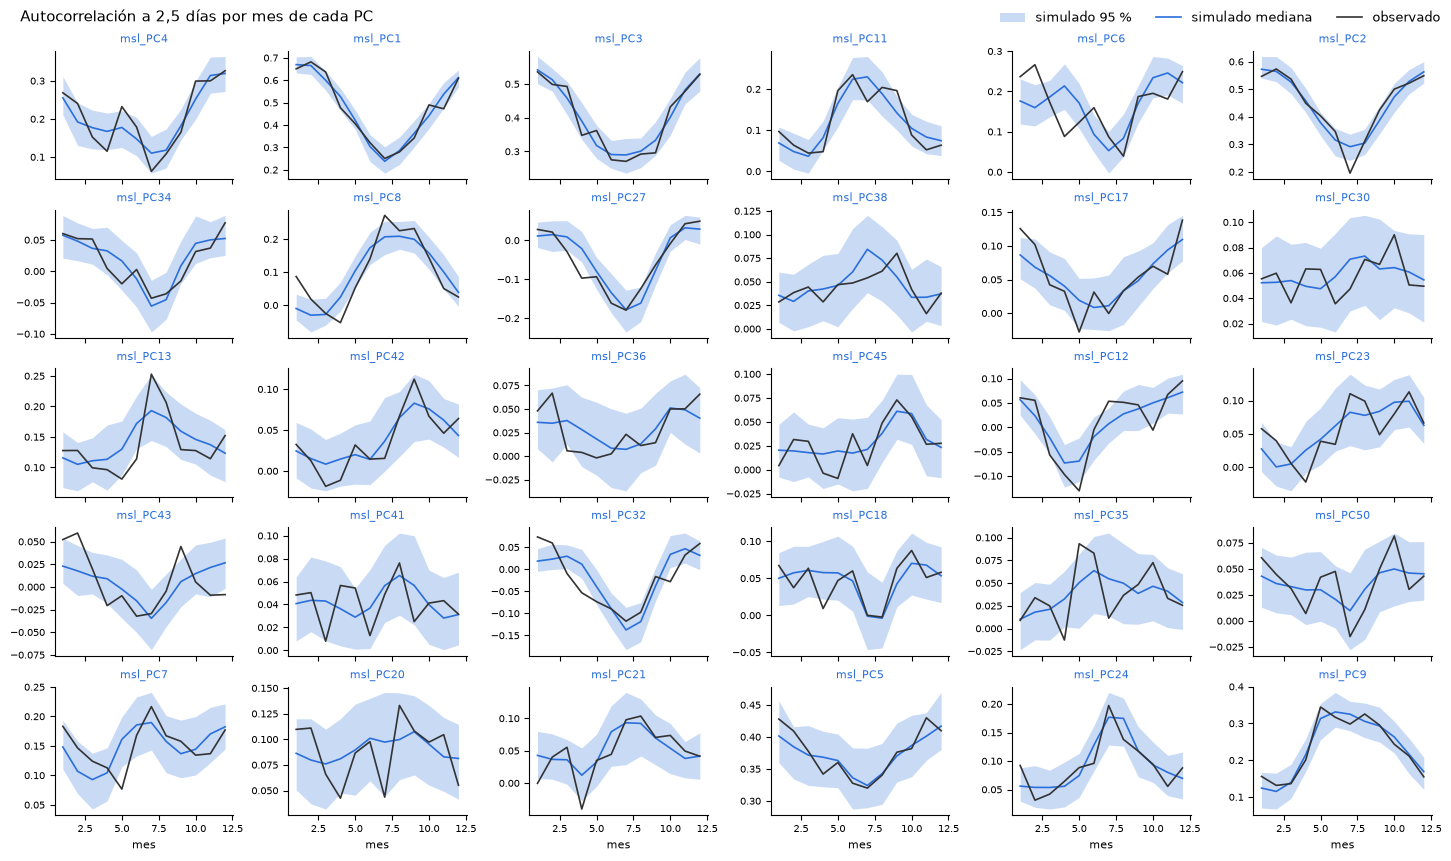

In [4]:
#### Autocorrelación por mes de inicio (para ver si la persistencia cambia con la estación)
def acf_mes(df, l):
    z = harm_std_pcs.transform(df)[cols]
    mes = z.index.month[:len(z) - l]
    a, b = z.values[:len(z) - l], z.values[l:]
    out = []
    for m in meses:
        am, bm = a[mes == m], b[mes == m]
        ok = ~(np.isnan(am) | np.isnan(bm)).any(1)
        am, bm = am[ok] - am[ok].mean(0), bm[ok] - bm[ok].mean(0)
        out.append((am * bm).mean(0) / (am.std(0) * bm.std(0)))
    return np.array(out)                                        # (12, pc)

for l, etiqueta in [(4, "1 día"), (10, "2,5 días")]:
    o = acf_mes(pcs_sel_6h, l)
    s = np.stack([acf_mes(df, l) for df in sims.values()])
    f = rejilla_banda(meses, o, s, "mes", f"Autocorrelación a {etiqueta} por mes de cada PC")
    f.savefig(f"outputs/var_6h/validacion/5_acf_mensual_{l * 6}h.png", dpi=150)
print("guardadas")

In [5]:
z_obs = harm_std_pcs.transform(pcs_sel_6h)
z_sim = harm_std_pcs.transform(sims[0])
pd.DataFrame({"obs": z_obs.groupby(z_obs.index.month).std().mean(1),
              "sim": z_sim.groupby(z_sim.index.month).std().mean(1)}).round(3)

C:\Users\alonsoap\AppData\Local\Temp\ipykernel_34372\934187824.py:3: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  pd.DataFrame({"obs": z_obs.groupby(z_obs.index.month).std().mean(1),
C:\Users\alonsoap\AppData\Local\Temp\ipykernel_34372\934187824.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  "sim": z_sim.groupby(z_sim.index.month).std().mean(1)}).round(3)


,obs,sim
1,0.998,1.036
2,0.999,1.027
3,1.002,0.985
4,0.998,0.971
5,0.999,0.998
6,0.999,1.009
7,1.000,1.017
8,0.995,1.017
9,1.003,1.004
10,1.002,0.976


In [6]:
z_sims = [harm_std_pcs.transform(s) for s in sims.values()]
ratio = pd.concat([z.groupby(z.index.month).std() for z in z_sims]).groupby(level=0).mean() \
        / z_obs.groupby(z_obs.index.month).std()
ratio.mean(1).round(3)            # por mes, media de las PCs

C:\Users\alonsoap\AppData\Local\Temp\ipykernel_34372\1042114036.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  ratio.mean(1).round(3)            # por mes, media de las PCs


1     1.038
2     1.027
3     0.983
4     0.974
5     0.991
6     1.013
7     1.012
8     1.018
9     1.005
10    0.981
11    0.976
12    1.005
dtype: float64

guardadas


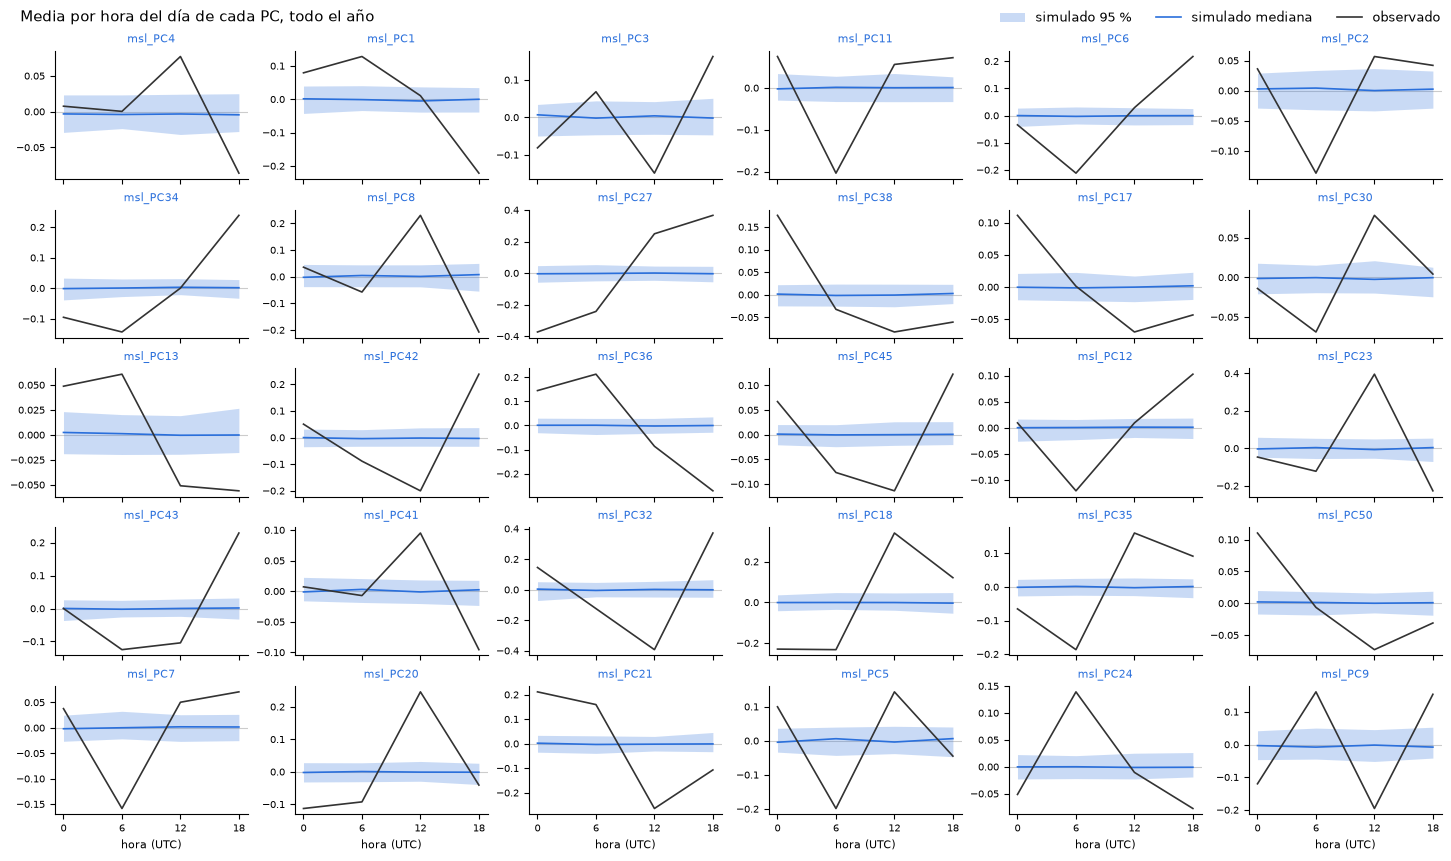

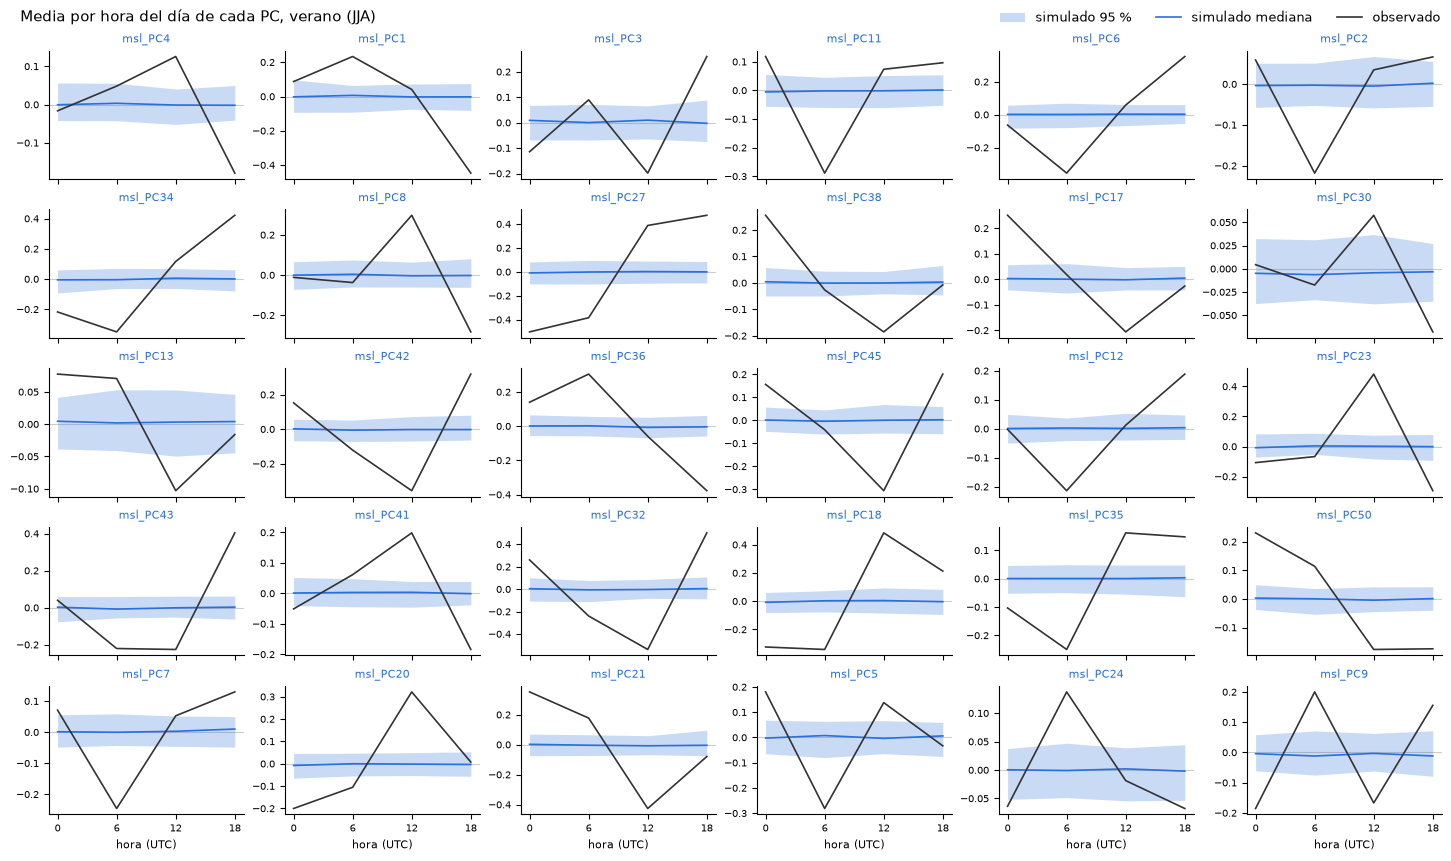

In [7]:
#### Ciclo diario: media de cada PC (estandarizada) por hora del día
horas = np.array([0, 6, 12, 18])

def media_hora(df, meses_sel=None):
    z = harm_std_pcs.transform(df)[cols]
    if meses_sel is not None:
        z = z[z.index.month.isin(meses_sel)]
    return z.groupby(z.index.hour).mean().reindex(horas).values      # (4, pc)

for meses_sel, etiqueta, fichero in [(None, "todo el año", "anual"), ([6, 7, 8], "verano (JJA)", "jja")]:
    o = media_hora(pcs_sel_6h, meses_sel)
    s = np.stack([media_hora(df, meses_sel) for df in sims.values()])
    f = rejilla_banda(horas, o, s, "hora (UTC)", f"Media por hora del día de cada PC, {etiqueta}")
    for ax in f.axes[:len(cols)]:
        ax.set_xticks(horas)
        ax.axhline(0, color="0.8", lw=0.8, zorder=0)
    f.savefig(f"outputs/var_6h/validacion/6_ciclo_diario_{fichero}.png", dpi=150)
print("guardadas")

In [10]:
from utils.tv_var.periodic_var import PeriodicVAR

#### Estilo presentación
TINTA, AZUL, NARANJA, GRIS, FONDO = "#13233A", "#2C6E91", "#C8622A", "#7A8594", "#F5F3EE"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Inter", "Arial", "DejaVu Sans"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "text.color": TINTA, "xtick.color": GRIS, "ytick.color": GRIS,
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.spines.top": False, "axes.spines.right": False,
})
os.makedirs("figuras", exist_ok=True)

PCS_EJ = ["msl_PC1", "msl_PC2", "msl_PC4", "msl_PC34"]          # 3 de baja varianza... de orden bajo y una alta
L1 = 4                                                           # 1 día = 4 pasos de 6 h
iu = np.triu_indices(len(cols), k=1)                             # 435 pares de PCs

def acf_mes_z(z, l):
    """Autocorrelación a l pasos por mes de inicio (12, pc)."""
    v = z.values; mes = z.index.month[:-l]
    a, b = v[:-l], v[l:]
    out = []
    for m in range(1, 13):
        am, bm = a[mes == m], b[mes == m]
        ok = ~(np.isnan(am) | np.isnan(bm)).any(1)
        am, bm = am[ok] - am[ok].mean(0), bm[ok] - bm[ok].mean(0)
        out.append((am * bm).mean(0) / (am.std(0) * bm.std(0)))
    return np.array(out)

def acf_z(z, lags=np.arange(21)):
    """Autocorrelación hasta 5 días (lags, pc)."""
    v = z.values - np.nanmean(z.values, 0); var = np.nanmean(v * v, 0)
    return np.array([np.nanmean(v[:len(v) - l] * v[l:], 0) / var for l in lags])

def stats_z(z):
    return {"acf_mes": acf_mes_z(z, L1), "acf": acf_z(z),
            "std_mes": z.groupby(z.index.month).std().values,
            "corr": np.corrcoef(z.dropna().values.T)[iu]}

#### Observado y PVAR (n_harm = 1), simulación a simulación
z_obs = harm_std_pcs.transform(pcs_sel_6h)[cols]
st_obs = stats_z(z_obs)
st_h1 = [stats_z(harm_std_pcs.transform(s)[cols]) for s in sims.values()]
pila = lambda lista, k: np.stack([d[k] for d in lista])
print(len(st_h1), "simulaciones")

100 simulaciones


In [11]:
var_h0 = PeriodicVAR(p=10, n_harm=0, freq="6h").fit(z_obs)
burn = int(pd.Timedelta(days=3 * 365) / pd.Timedelta("6h"))
st_h0 = [stats_z(var_h0.simulate(n_years=87, start="1940-01-01", seed=i, burn=burn)[cols]) for i in range(20)]

c:\Users\alonsoap\Documents\Proyectos\two_stage_model\utils\tv_var\periodic_var.py:178: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  LAG_MATRIX[f'{col}_lag_{i+1}'] = delay[col].values
c:\Users\alonsoap\Documents\Proyectos\two_stage_model\utils\tv_var\periodic_var.py:178: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  LAG_MATRIX[f'{col}_lag_{i+1}'] = delay[col].values
c:\Users\alonsoap\Documents\Proyectos\two_stage_model\utils\tv_var\periodic_var.py:178: PerformanceWarning: DataFrame is highly fragmented.  This is usually the res

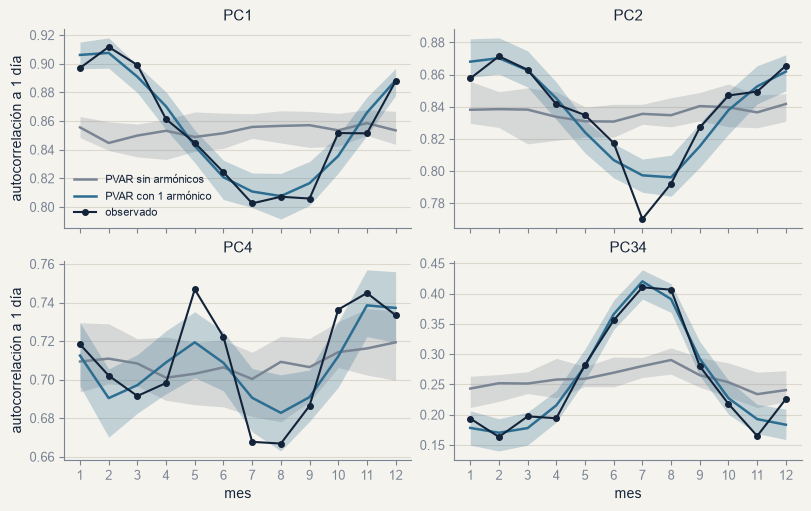

In [12]:
meses = np.arange(1, 13)
a1, a0 = pila(st_h1, "acf_mes"), pila(st_h0, "acf_mes")

fig, axs = plt.subplots(2, 2, figsize=(8.0, 5.0), constrained_layout=True, sharex=True)
for ax, pc in zip(axs.flat, PCS_EJ):
    j = cols.index(pc)
    for arr, color, lab in [(a0, GRIS, "PVAR sin armónicos"), (a1, AZUL, "PVAR con 1 armónico")]:
        p5, p50, p95 = np.percentile(arr[:, :, j], [5, 50, 95], axis=0)
        ax.fill_between(meses, p5, p95, color=color, alpha=0.25, lw=0)
        ax.plot(meses, p50, color=color, lw=1.8, label=lab)
    ax.plot(meses, st_obs["acf_mes"][:, j], "o-", color=TINTA, lw=1.5, ms=4, label="observado")
    ax.set(title=pc.replace("msl_", ""), xticks=meses)
    ax.grid(axis="y", color="#DDD8CE", lw=0.8); ax.set_axisbelow(True)
for ax in axs[1]: ax.set_xlabel("mes")
for ax in axs[:, 0]: ax.set_ylabel("autocorrelación a 1 día")
axs[0, 0].legend(frameon=False, fontsize=8, loc="lower left")
fig.savefig("figuras/pvar_coef_estacional.png", dpi=200)
plt.show()

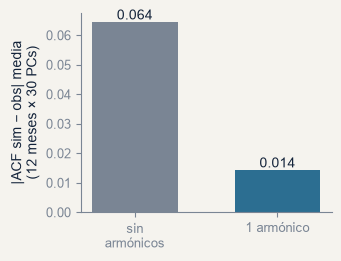

In [13]:
err0 = np.abs(np.median(a0, 0) - st_obs["acf_mes"]).mean()
err1 = np.abs(np.median(a1, 0) - st_obs["acf_mes"]).mean()

fig, ax = plt.subplots(figsize=(3.3, 2.5), constrained_layout=True)
ax.bar([0, 1], [err0, err1], color=[GRIS, AZUL], width=0.6)
for x, v in zip([0, 1], [err0, err1]):
    ax.text(x, v, f"{v:.3f}", ha="center", va="bottom", fontsize=10)
ax.set_xticks([0, 1], ["sin\narmónicos", "1 armónico"])
ax.set(ylabel="|ACF sim − obs| media\n(12 meses × 30 PCs)")
fig.savefig("figuras/pvar_acf_mes.png", dpi=200)
plt.show()

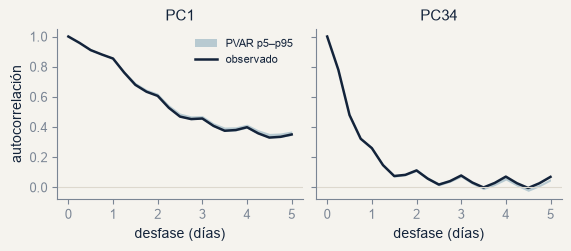

In [14]:
dias = np.arange(21) / 4
fig, axs = plt.subplots(1, 2, figsize=(5.6, 2.4), constrained_layout=True, sharey=True)
for ax, pc in zip(axs, ["msl_PC1", "msl_PC34"]):
    j = cols.index(pc)
    p5, p95 = np.percentile(pila(st_h1, "acf")[:, :, j], [5, 95], axis=0)
    ax.fill_between(dias, p5, p95, color=AZUL, alpha=0.3, lw=0, label="PVAR p5–p95")
    ax.plot(dias, st_obs["acf"][:, j], color=TINTA, lw=1.8, label="observado")
    ax.axhline(0, color="#DDD8CE", lw=0.8)
    ax.set(title=pc.replace("msl_", ""), xlabel="desfase (días)")
axs[0].set_ylabel("autocorrelación")
axs[0].legend(frameon=False, fontsize=8)
fig.savefig("figuras/pvar_acf.png", dpi=200)
plt.show()

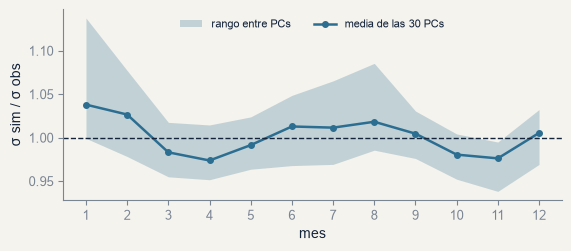

In [15]:
ratio = pila(st_h1, "std_mes").mean(0) / st_obs["std_mes"]            # (12, pc)
fig, ax = plt.subplots(figsize=(5.6, 2.4), constrained_layout=True)
ax.fill_between(meses, ratio.min(1), ratio.max(1), color=AZUL, alpha=0.25, lw=0, label="rango entre PCs")
ax.plot(meses, ratio.mean(1), "o-", color=AZUL, lw=1.8, ms=4, label="media de las 30 PCs")
ax.axhline(1, color=TINTA, ls="--", lw=1)
ax.set(xlabel="mes", ylabel="σ sim / σ obs", xticks=meses)
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper center")
fig.savefig("figuras/pvar_std_mes.png", dpi=200)
plt.show()

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


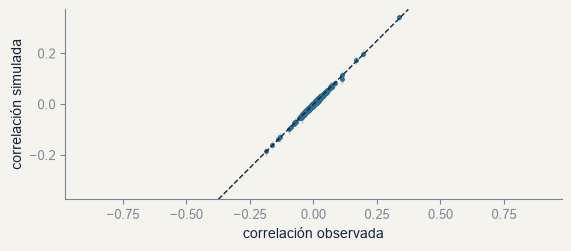

In [16]:
c_sim = pila(st_h1, "corr")
p5, p50, p95 = np.percentile(c_sim, [5, 50, 95], axis=0)
fig, ax = plt.subplots(figsize=(5.6, 2.4), constrained_layout=True)
ax.vlines(st_obs["corr"], p5, p95, color=AZUL, alpha=0.3, lw=1)
ax.plot(st_obs["corr"], p50, "o", color=AZUL, ms=2.5)
lim = np.abs(np.r_[st_obs["corr"], p95, p5]).max() * 1.05
ax.plot([-lim, lim], [-lim, lim], color=TINTA, ls="--", lw=1)
ax.set(xlabel="correlación observada", ylabel="correlación simulada", xlim=(-lim, lim), ylim=(-lim, lim))
ax.set_aspect("equal", adjustable="datalim")
fig.savefig("figuras/pvar_corr_cruzada.png", dpi=200)
plt.show()